# Spaceship Titanic (Kaggle): versão 2

**Objetivo:** prever quais passageiros da nave foram transportados para outra dimensão (classificação binária), a partir de planeta de origem, cabine, idade e gastos a bordo. São 8.693 passageiros no treino.

**O que mudou em relação à versão 1:**
- A v1 aplicava one-hot ao ID e ao nome do passageiro: milhares de colunas sem sinal. A v2 extrai **grupo de viagem** do ID e **deck/lado** da cabine, e descarta o nome.
- A v1 imputava ausentes com médias calculadas antes da divisão treino/validação (vazamento). A v2 faz tudo dentro de um **pipeline**, aprendido só no treino de cada dobra.
- A v1 avaliava numa única separação de 20%. A v2 usa **validação cruzada estratificada de 5 dobras** e compara as duas versões no mesmo protocolo.

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline

sys.path.insert(0, "../..")  # estilo compartilhado do repositório
from comum.estilo import COR, aplicar, br, fonte, subtitulo
from features import CATEGORICAS, NUMERICAS, criar_variaveis, pre_processador

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: Kaggle, competição Spaceship Titanic · elaboração: Cézar Bento"

treino = pd.read_csv("train.csv")
teste = pd.read_csv("test.csv")
print(f"Treino: {br(len(treino))} passageiros · teste: {br(len(teste))} · transportados: {treino.Transported.mean():.1%}")
print()
print(treino.isna().mean().mul(100).round(1).rename("% ausente").to_string())

Treino: 8.693 passageiros · teste: 4.277 · transportados: 50.4%

PassengerId     0.0
HomePlanet      2.3
CryoSleep       2.5
Cabin           2.3
Destination     2.1
Age             2.1
VIP             2.3
RoomService     2.1
FoodCourt       2.1
ShoppingMall    2.4
Spa             2.1
VRDeck          2.2
Name            2.3
Transported     0.0


## 1. O que explica ser transportado

CryoSleep
Acordado              32.9
Em sono criogênico    81.8
sem_gasto
Gastou a bordo     29.9
Não gastou nada    78.6


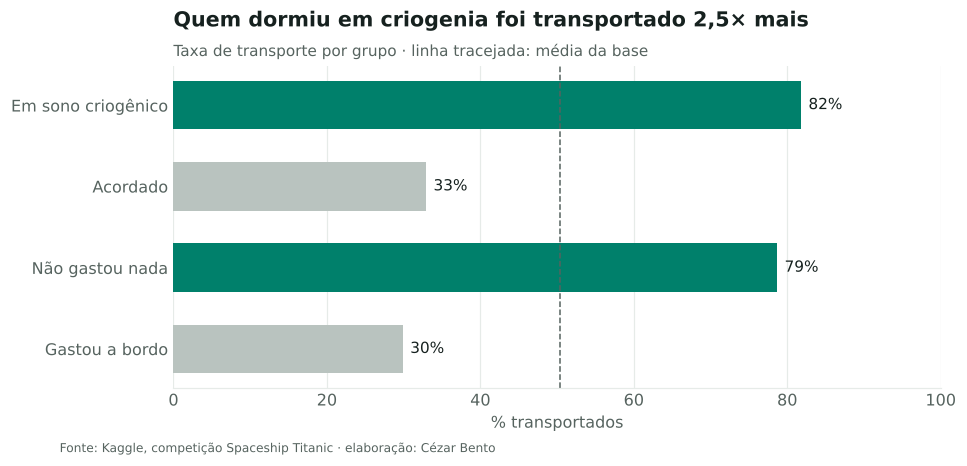

In [2]:
X = criar_variaveis(treino)
y = treino["Transported"].astype(int)

def taxa(col):
    return X.groupby(col)["Transported"].mean().mul(100)

cripto = taxa(X["CryoSleep"].map({1.0: "Em sono criogênico", 0.0: "Acordado"}))
gasto = taxa(X["sem_gasto"].map({1.0: "Não gastou nada", 0.0: "Gastou a bordo"}))
print(cripto.round(1).to_string()); print(gasto.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
rotulos = ["Em sono criogênico", "Acordado", "Não gastou nada", "Gastou a bordo"]
valores = [cripto["Em sono criogênico"], cripto["Acordado"], gasto["Não gastou nada"], gasto["Gastou a bordo"]]
cores = [COR["principal"], COR["contexto"], COR["principal"], COR["contexto"]]
ax.barh(rotulos[::-1], valores[::-1], color=cores[::-1], height=0.6)
for i, v in enumerate(valores[::-1]):
    ax.text(v + 1, i, f"{br(v)}%", va="center", fontsize=10, color=COR["texto"])
ax.axvline(y.mean() * 100, color=COR["texto2"], lw=1, ls="--")
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xlabel("% transportados")
ax.set_title(f"Quem dormiu em criogenia foi transportado {br(cripto.iloc[1] / cripto.iloc[0], 1)}× mais")
subtitulo(ax, "Taxa de transporte por grupo · linha tracejada: média da base")
fonte(fig, FONTE)
fig.savefig("figuras/01_criogenia_gasto.png")

lado     P     S
deck            
A     43.6  54.7
B     67.4  78.4
C     58.1  76.4
D     40.3  46.5
E     34.3  37.1
F     41.1  47.1
G     44.8  58.4


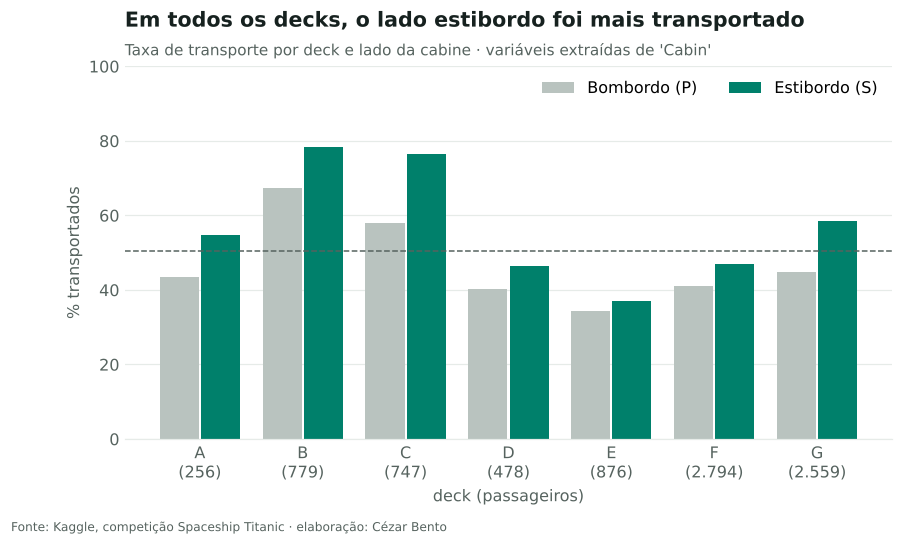

In [3]:
tab = X.pivot_table(index="deck", columns="lado", values="Transported", aggfunc="mean").mul(100)
tab = tab.drop(index="T", errors="ignore")  # deck T tem só 5 passageiros
cont = X.groupby("deck").size()
print(tab.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(tab))
ax.bar(x - 0.2, tab["P"], width=0.38, color=COR["contexto"], label="Bombordo (P)")
ax.bar(x + 0.2, tab["S"], width=0.38, color=COR["principal"], label="Estibordo (S)")
ax.axhline(y.mean() * 100, color=COR["texto2"], lw=1, ls="--")
ax.set_xticks(x, [f"{d}\n({br(cont[d])})" for d in tab.index])
ax.set_xlabel("deck (passageiros)"); ax.set_ylabel("% transportados"); ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False); ax.legend(loc="upper right", ncol=2)
ax.set_title("Em todos os decks, o lado estibordo foi mais transportado")
subtitulo(ax, "Taxa de transporte por deck e lado da cabine · variáveis extraídas de 'Cabin'")
fonte(fig, FONTE, y=-0.06)
fig.savefig("figuras/02_deck_lado.png")

## 2. Versão 1 × versão 2 no mesmo protocolo

Para comparar de forma justa, a v1 é reproduzida (one-hot de todas as colunas, incluindo ID e nome) e avaliada com a mesma validação cruzada.

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)

# Versão 1: imputação simples, one-hot em tudo (ID, nome e cabine viram milhares de colunas)
v1 = treino.drop(columns="Transported").copy()
num_v1 = v1.select_dtypes("number").columns
v1[num_v1] = v1[num_v1].fillna(v1[num_v1].mean())
v1 = pd.get_dummies(v1.fillna(v1.mode().iloc[0]))
print(f"Versão 1: {br(v1.shape[1])} colunas")
acc_v1 = cross_val_score(RandomForestClassifier(100, random_state=42, n_jobs=-1), v1, y, cv=cv)

modelos = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42),
}
print(f"Versão 2: {len(NUMERICAS) + len(CATEGORICAS)} variáveis antes do one-hot")
resultados = {"v1 · Random Forest": acc_v1}
for nome, modelo in modelos.items():
    resultados[f"v2 · {nome}"] = cross_val_score(make_pipeline(pre_processador(), modelo), X, y, cv=cv)
res = pd.DataFrame({k: {"acurácia média": v.mean(), "desvio": v.std()} for k, v in resultados.items()}).T
print((res * 100).round(2).to_string())

Versão 1: 23.742 colunas
Versão 2: 16 variáveis antes do one-hot
                          acurácia média  desvio
v1 · Random Forest                 78.51    0.55
v2 · Regressão logística           77.33    1.14
v2 · Random Forest                 80.81    0.82
v2 · Gradient boosting             81.05    0.61


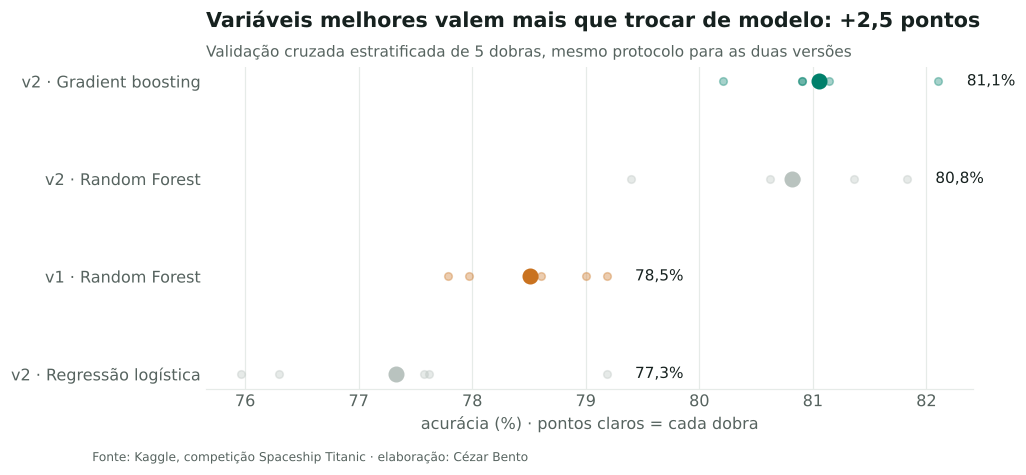

In [5]:
ordem = res.sort_values("acurácia média").index
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(ordem))
for i, nome in enumerate(ordem):
    vals = resultados[nome] * 100
    cor = COR["destaque"] if nome.startswith("v1") else COR["principal"] if nome == ordem[-1] else COR["contexto"]
    ax.scatter(vals, np.full(len(vals), i), color=cor, alpha=0.35, s=25)
    ax.scatter(vals.mean(), i, color=cor, s=90, zorder=3)
    ax.text(vals.max() + 0.25, i, f"{br(vals.mean(), 1)}%", va="center", fontsize=10, color=COR["texto"])
ax.set_yticks(yy, ordem); ax.grid(axis="y", visible=False); ax.set_xlabel("acurácia (%) · pontos claros = cada dobra")
ganho = res.loc[ordem[-1], "acurácia média"] - res.loc["v1 · Random Forest", "acurácia média"]
ax.set_title(f"Variáveis melhores valem mais que trocar de modelo: +{br(ganho * 100, 1)} pontos")
subtitulo(ax, "Validação cruzada estratificada de 5 dobras, mesmo protocolo para as duas versões")
fonte(fig, FONTE, y=-0.04)
fig.savefig("figuras/03_v1_v2.png")

**Leitura:** com as variáveis novas, até a Random Forest da v1 sobe para cerca de 81%. A troca de modelo (Random Forest → gradient boosting) acrescenta pouco. As variáveis certas importam mais do que o algoritmo.

## 3. Quais variáveis o modelo usa

Não gastou nada        -0.01
VIP                    -0.01
Planeta de origem       0.06
Tamanho do grupo        0.08
Destino                 0.38
Idade                   0.74
Shopping                0.78
Número da cabine        1.59
Lado da cabine          1.68
Serviço de quarto       1.85
Gasto total             2.01
Deck                    2.22
Praça de alimentação    2.88
Spa                     3.75
VR Deck                 4.08
Sono criogênico         4.51


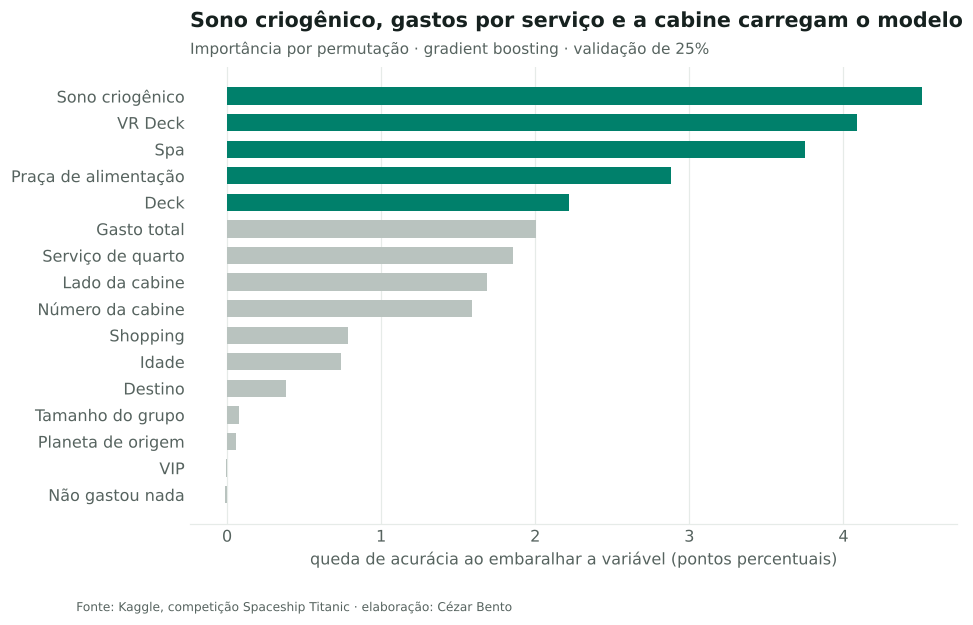

In [6]:
# Importância por permutação numa validação separada: quanto a acurácia cai ao embaralhar cada variável
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
final = make_pipeline(pre_processador(), HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42))
final.fit(Xa, ya)
colunas = NUMERICAS + CATEGORICAS
imp = permutation_importance(final, Xb[colunas], yb, n_repeats=10, random_state=42, scoring="accuracy")
importancia = pd.Series(imp.importances_mean, index=colunas).sort_values()
nomes = {"log_gasto": "Gasto total", "log_Spa": "Spa", "log_VRDeck": "VR Deck", "log_RoomService": "Serviço de quarto",
         "log_FoodCourt": "Praça de alimentação", "log_ShoppingMall": "Shopping", "CryoSleep": "Sono criogênico",
         "num_cabine": "Número da cabine", "deck": "Deck", "lado": "Lado da cabine", "HomePlanet": "Planeta de origem",
         "Destination": "Destino", "Age": "Idade", "tam_grupo": "Tamanho do grupo", "sem_gasto": "Não gastou nada", "VIP": "VIP"}
importancia.index = [nomes.get(c, c) for c in importancia.index]
print((importancia * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5.4))
cores = [COR["principal"] if v >= importancia.iloc[-5] else COR["contexto"] for v in importancia]
ax.barh(importancia.index, importancia * 100, color=cores, height=0.65)
ax.grid(axis="y", visible=False); ax.set_xlabel("queda de acurácia ao embaralhar a variável (pontos percentuais)")
ax.set_title("Sono criogênico, gastos por serviço e a cabine carregam o modelo")
subtitulo(ax, "Importância por permutação · gradient boosting · validação de 25%")
fonte(fig, FONTE)
fig.savefig("figuras/04_importancia.png")

## 4. Submissão

In [7]:
final.fit(X, y)
previsao = final.predict(criar_variaveis(teste)).astype(bool)
pd.DataFrame({"PassengerId": teste["PassengerId"], "Transported": previsao}).to_csv("submission.csv", index=False)
print(f"submission.csv: {br(len(previsao))} linhas · transportados previstos: {previsao.mean():.1%}")

submission.csv: 4.277 linhas · transportados previstos: 50.5%


## Limitações e próximos passos

- Membros do mesmo grupo de viagem tendem a ter o mesmo destino. Uma validação por grupo (`GroupKFold`) daria uma estimativa mais conservadora, e usar a informação do grupo para imputar cabine e planeta de origem pode ganhar mais alguns décimos.
- A acurácia dos melhores colocados no Kaggle fica em torno de 81% a 82%: o ganho restante é pequeno e vem mais de ajuste fino do que de ideias novas.